In [ ]:
import os
import shutil

# Define paths
base_train = '/content/cats_dogs_light/train'
cat_dir = os.path.join(base_train, 'cats')
dog_dir = os.path.join(base_train, 'dogs')

# Create 'cats' and 'dogs' directories if they don't exist
os.makedirs(cat_dir, exist_ok=True)
os.makedirs(dog_dir, exist_ok=True)

# Move loose images into their respective folders
for filename in os.listdir(base_train):
    file_path = os.path.join(base_train, filename)

    # Skip if it's a directory (like the new 'cats' or 'dogs' folders)
    if os.path.isdir(file_path):
        continue

    if filename.startswith('cat.'):
        shutil.move(file_path, os.path.join(cat_dir, filename))
    elif filename.startswith('dog.'):
        shutil.move(file_path, os.path.join(dog_dir, filename))

print("✅ Training images successfully sorted into 'cats' and 'dogs' folders!")


import os
import shutil

# Define test path
base_test = '/content/cats_dogs_light/test'
cat_test_dir = os.path.join(base_test, 'cats')
dog_test_dir = os.path.join(base_test, 'dogs')

# Create 'cats' and 'dogs' directories if they don't exist
os.makedirs(cat_test_dir, exist_ok=True)
os.makedirs(dog_test_dir, exist_ok=True)

# Move loose test images into their respective folders
for filename in os.listdir(base_test):
    file_path = os.path.join(base_test, filename)

    # Skip if it's already a directory
    if os.path.isdir(file_path):
        continue

    if filename.startswith('cat.'):
        shutil.move(file_path, os.path.join(cat_test_dir, filename))
    elif filename.startswith('dog.'):
        shutil.move(file_path, os.path.join(dog_test_dir, filename))

print("✅ Test images successfully sorted into 'cats' and 'dogs' folders!")

✅ Training images successfully sorted into 'cats' and 'dogs' folders!
✅ Test images successfully sorted into 'cats' and 'dogs' folders!


In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras.layers import Convolution2D,Dense,Flatten
from keras import Sequential
from keras.applications.vgg16 import VGG16

In [ ]:
conv_base = VGG16(
      weights='imagenet',
      include_top=False,
      input_shape=(150,150,3)
)

In [ ]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_9 (InputLayer)      │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 14,714,688 (56.13 MB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
conv_base.trainable = False

In [ ]:
model = Sequential()

model.add(conv_base)
model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [ ]:
model.summary()

Model: "sequential_6"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ vgg16 (Functional)              │ (None, 4, 4, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_6 (Flatten)             │ (None, 8192)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_12 (Dense)                │ (None, 256)            │     2,097,408 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_13 (Dense)                │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 16,812,353 (64.13 MB)

 Trainable params: 2,097,665 (8.00 MB)

 Non-trainable params: 14,714,688 (56.13 MB)

Generators

In [ ]:
# train_ds = keras.utils.image_dataset_from_directory(
#     '/content/cats_dogs_light/train',
#     labels='inferred',
#     label_mode='int',
#     image_size=(150, 150),
#     batch_size=32
# )

# validation_ds = keras.utils.image_dataset_from_directory(
#     '/content/cats_dogs_light/test',
#     labels='inferred',
#     label_mode='int',
#     image_size=(150, 150),
#     batch_size=32
# )

Found 1000 files belonging to 2 classes.
Found 400 files belonging to 2 classes.


Now we are using data Augmentation for reducing the overfitting

In [ ]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

batch_size = 32

train_datagen = ImageDataGenerator(
    rescale=1. / 255,
    shear_range=0.2,
    zoom_range=0.2,
    horizontal_flip=True
)

test_datagen = ImageDataGenerator(rescale=1. / 255)

train_generator = train_datagen.flow_from_directory(
    '/content/cats_dogs_light/train',
    target_size=(150, 150),  # Corrected typo here
    batch_size=batch_size,
    class_mode='binary'
)

validation_generator = test_datagen.flow_from_directory(
    '/content/cats_dogs_light/test',
    target_size=(150, 150),
    batch_size=batch_size,
    class_mode='binary'
)

print("✅ Generators created successfully!")

Found 1000 images belonging to 2 classes.
Found 400 images belonging to 2 classes.
✅ Generators created successfully!


Now we are not using the Normalization part

In [ ]:
# ## Normalize
# def Normalize(image,label):
#   image = tf.cast(image/255.,tf.float32)
#   label = tf.cast(label,tf.float32)
#   return image,label

# train_ds = train_ds.map(Normalize)
# test_ds = validation_ds.map(Normalize)

In [ ]:
model.compile(optimizer='adam',loss='binary_crossentropy',metrics=['accuracy'])

In [ ]:
## Early Stopping
from tensorflow import keras
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.0001,
    patience=20,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)


In [ ]:
history = model.fit(train_generator,validation_data=validation_generator,epochs=10,callbacks=[early_stopping])

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 9s 272ms/step - accuracy: 0.9720 - loss: 0.0666 - val_accuracy: 0.8750 - val_loss: 0.3180
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 259ms/step - accuracy: 0.9810 - loss: 0.0561 - val_accuracy: 0.8625 - val_loss: 0.4723
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 255ms/step - accuracy: 0.9840 - loss: 0.0616 - val_accuracy: 0.8700 - val_loss: 0.4405
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 258ms/step - accuracy: 0.9840 - loss: 0.0414 - val_accuracy: 0.8775 - val_loss: 0.3840
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 10s 326ms/step - accuracy: 0.9900 - loss: 0.0343 - val_accuracy: 0.8800 - val_loss: 0.3554
Epoch 6/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 262ms/step - accuracy: 0.9820 - loss: 0.0471 - val_accuracy: 0.8875 - val_loss: 0.3745
Epoch 7/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 256ms/step - accuracy: 0.9830 - loss: 0.0405 - val_accuracy: 0.8750 - val_loss: 0.4387
Epoch 8/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 8s 259ms/step - accuracy: 0.9880 - loss: 0.0482 - val_accuracy: 0

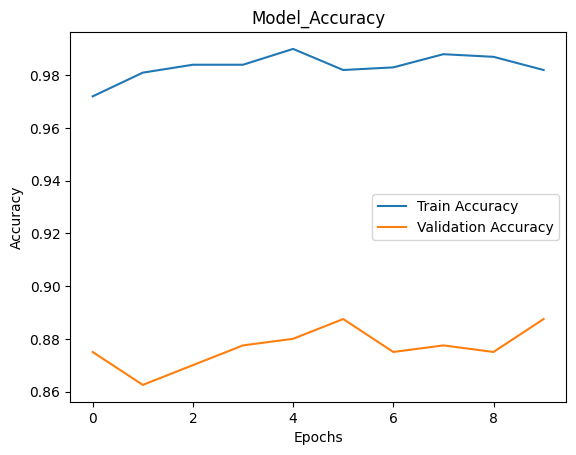

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model_Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()  # This will now successfully display both labels
plt.show()

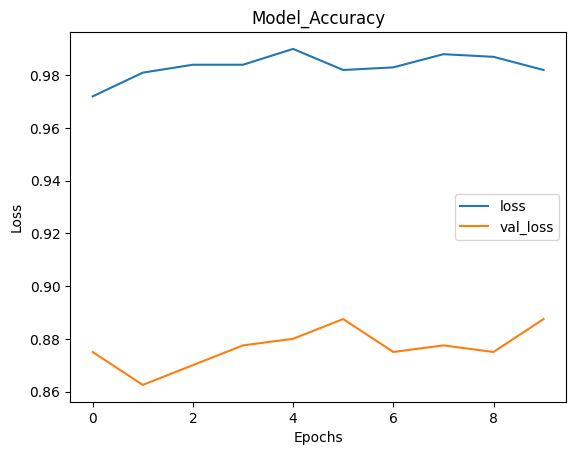

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='loss')
plt.plot(history.history['val_accuracy'], label='val_loss')

plt.title('Model_Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()  # This will now successfully display both labels
plt.show()

NOW FOR USIGN PRETRAINED MODEL BY METHOD FINE TUNING

In [ ]:
import tensorflow as tf
from tensorflow import keras
from keras.layers import Convolution2D,Dense,Flatten
from keras import Sequential
from keras.applications.vgg16 import VGG16

In [ ]:
conv_base = VGG16(
    weights='imagenet',
    include_top=False,
    input_shape=(150,150,3)
)

In [ ]:
conv_base.trainable = True
set_trainable = False

for layer in conv_base.layers :
  if layer.name == 'block5_conv1':
    set_trainable = True
  if set_trainable:
    layer.trainable = True
  else :
    layer.trainable = False

for layer in conv_base.layers :
  print(layer.name,layer.trainable)

input_layer_12 False
block1_conv1 False
block1_conv2 False
block1_pool False
block2_conv1 False
block2_conv2 False
block2_pool False
block3_conv1 False
block3_conv2 False
block3_conv3 False
block3_pool False
block4_conv1 False
block4_conv2 False
block4_conv3 False
block4_pool False
block5_conv1 True
block5_conv2 True
block5_conv3 True
block5_pool True


In [ ]:
conv_base.summary()

Model: "vgg16"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_12 (InputLayer)     │ (None, 150, 150, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv1 (Conv2D)           │ (None, 150, 150, 64)   │         1,792 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_conv2 (Conv2D)           │ (None, 150, 150, 64)   │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block1_pool (MaxPooling2D)      │ (None, 75, 75, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv1 (Conv2D)           │ (None, 75, 75, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_conv2 (Conv2D)           │ (None, 75, 75, 128)    │       147,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block2_pool (MaxPooling2D)      │ (None, 37, 37, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv1 (Conv2D)           │ (None, 37, 37, 256)    │       295,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv2 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_conv3 (Conv2D)           │ (None, 37, 37, 256)    │       590,080 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block3_pool (MaxPooling2D)      │ (None, 18, 18, 256)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv1 (Conv2D)           │ (None, 18, 18, 512)    │     1,180,160 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv2 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_conv3 (Conv2D)           │ (None, 18, 18, 512)    │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block4_pool (MaxPooling2D)      │ (None, 9, 9, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv1 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv2 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_conv3 (Conv2D)           │ (None, 9, 9, 512)      │     2,359,808 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ block5_pool (MaxPooling2D)      │ (None, 4, 4, 512)      │             0 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,714,688 (56.13 MB)

 Trainable params: 7,079,424 (27.01 MB)

 Non-trainable params: 7,635,264 (29.13 MB)

In [ ]:
model = Sequential()

model.add(conv_base)
model.add(Flatten())
model.add(Dense(256,activation='relu'))
model.add(Dense(1,activation='sigmoid'))

In [ ]:
train_ds = keras.utils.image_dataset_from_directory(
    '/content/cats_dogs_light/train',
    labels='inferred',
    label_mode='int',
    image_size=(150, 150),
    batch_size=32
)

validation_ds = keras.utils.image_dataset_from_directory(
    '/content/cats_dogs_light/test',
    labels='inferred',
    label_mode='int',
    image_size=(150, 150),
    batch_size=32
)

Found 1000 files belonging to 2 classes.
Found 400 files belonging to 2 classes.


In [ ]:
## Normalize
def Normalize(image,label):
  image = tf.cast(image/255.,tf.float32)
  label = tf.cast(label,tf.float32)
  return image,label

train_ds = train_ds.map(Normalize)
test_ds = validation_ds.map(Normalize)

In [ ]:
model.compile(
    optimizer= keras.optimizers.RMSprop(learning_rate=1e-5),
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [ ]:
## Early Stopping
from tensorflow import keras
early_stopping = keras.callbacks.EarlyStopping(
    monitor="val_loss",
    min_delta=0.0001,
    patience=3,
    verbose=1,
    mode="auto",
    baseline=None,
    restore_best_weights=False,
    start_from_epoch=0,
)


In [ ]:
history = model.fit(train_ds,validation_data=validation_ds,epochs=10,callbacks=[early_stopping])

Epoch 1/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 111ms/step - accuracy: 1.0000 - loss: 0.0232 - val_accuracy: 0.8175 - val_loss: 26.7311
Epoch 2/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - accuracy: 1.0000 - loss: 0.0141 - val_accuracy: 0.8800 - val_loss: 14.7022
Epoch 3/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 114ms/step - accuracy: 1.0000 - loss: 0.0110 - val_accuracy: 0.8575 - val_loss: 21.3920
Epoch 4/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 115ms/step - accuracy: 1.0000 - loss: 0.0082 - val_accuracy: 0.8300 - val_loss: 28.7309
Epoch 5/10
32/32 ━━━━━━━━━━━━━━━━━━━━ 4s 117ms/step - accuracy: 1.0000 - loss: 0.0064 - val_accuracy: 0.8300 - val_loss: 30.5780
Epoch 5: early stopping


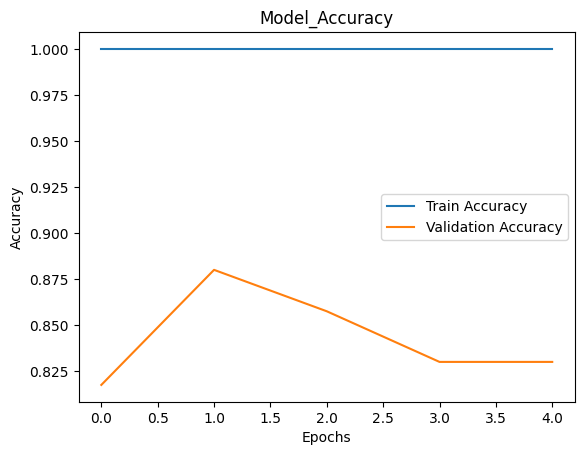

In [ ]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')

plt.title('Model_Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()  # This will now successfully display both labels
plt.show()